# DISTRIBUIÇÃO DAS HABILIDADES NAS QUESTÕES

## Hipótese

Cada área de conhecimento avaliada no enem é dividida em 30 habilidades. É natural esperarmos que essa distribuição aconteça de forma equilibrada, visto que todas as habilidades devem ter a mesma importância na formação do estudante. Porém é impossível uma distribuição completamente igual de habilidades, visto que cada área do conhecimento contém 30 habilidades mas consta de 45 questões na prova. 

Apesar de existir a possibilidade de uma questão trabalhar mais de uma habilidade, a fonte dos dados associa apenas uma única habilidade por questão. Portanto tratamos nesse projeto cada questão como avaliativa de apenas uma habilidade.

O objetivo desse ponto do projeto é analisar se essa distribuição de fato se aproxima de uma uniformidade. Também buscamos identificar quais habilidade são cobradas com mais frequência em cada área do conhecimento, possibilitanto assim uma melhor preparação do estudante e um melhor conhecimento da estrutura da prova.

## Metodologia e engenharia

Para essa etapa, criamos uma tabela mart contendo a área do conhecimento, a habilidade, a descrição completa e o número de vezes que essa habilidade apareceu ao longo do período considerado. Como o banco de dados não se limita às aplicações regulares das provas, a soma dos valores de frequência ultrapassa o valor de 900 questões esperado.

Ordenamos o dataframe resultante da consulta dessa tabela baseado na frequência das habilidades. Dessa forma, conseguiremos estabelecer um ranking e apresentar um "top 5" com as habilidades mais frequentes dentro de cada área do conhecimento.

## Importação de dados

In [2]:
import pandas as pd
import duckdb 

# abrir a conexão com banco de dados
con = duckdb.connect('../database/enem.duckdb')

# criar a consulta SQL
query = """ 
WITH Rank_habilidades AS (
    SELECT 
        SG_AREA,
        CO_HABILIDADE,
        habilidade_descricao,
        quantidade_questoes,
        ROW_NUMBER() OVER (PARTITION BY SG_AREA ORDER BY quantidade_questoes DESC) as ranking
    FROM mart_frequencia
)
SELECT 
    SG_AREA AS "Área do conhecimento", 
    CO_HABILIDADE AS Habilidade, 
    habilidade_descricao AS "Descrição",
    quantidade_questoes AS Quantidade,
    ranking
FROM Rank_habilidades
WHERE ranking <= 5
ORDER BY 
	SG_AREA,
	ranking 
"""

# consultar a tabela e salvar em um dataframe
df = con.execute(query).df()

#Não esquecer de fechar a conexão
con.close()

# visualizar o dataframe
df

,Área do conhecimento,Habilidade,Descrição,Quantidade,ranking
0,CH,3,associar as manifestações culturais do present...,25,1
1,CH,23,analisar a importância dos valores éticos na e...,21,2
2,CH,15,"avaliar criticamente conflitos culturais, soci...",20,3
3,CH,11,identificar registros de práticas de grupos so...,20,4
4,CH,1,interpretar historicamente e/ou geograficament...,20,5
5,CN,5,dimensionar circuitos ou dispositivos elétrico...,22,1
6,CN,17,relacionar informações apresentadas em diferen...,21,2
7,CN,18,"relacionar propriedades físicas, químicas ou b...",20,3
8,CN,10,"analisar perturbações ambientais, identificand...",20,4
9,CN,12,avaliar impactos em ambientes naturais decorre...,19,5


## Estratégia de visualização

Geramos gráficos individuais para cada área do conhecimento. Dessa forma nossa análise fica mais isolada e podemos avaliar as áreas individualmente. Gráficos de barra horizontal já trazem uma visão imediata de qual habilidade se destaca em frequência.

Logo abaixo dos gráficos há um dataframe que traz a descrição completa das habilidades citadas. Essa divisão permite manter limpa a visualização gráfica ao trazer os longos textos separadamente.

## Visualização

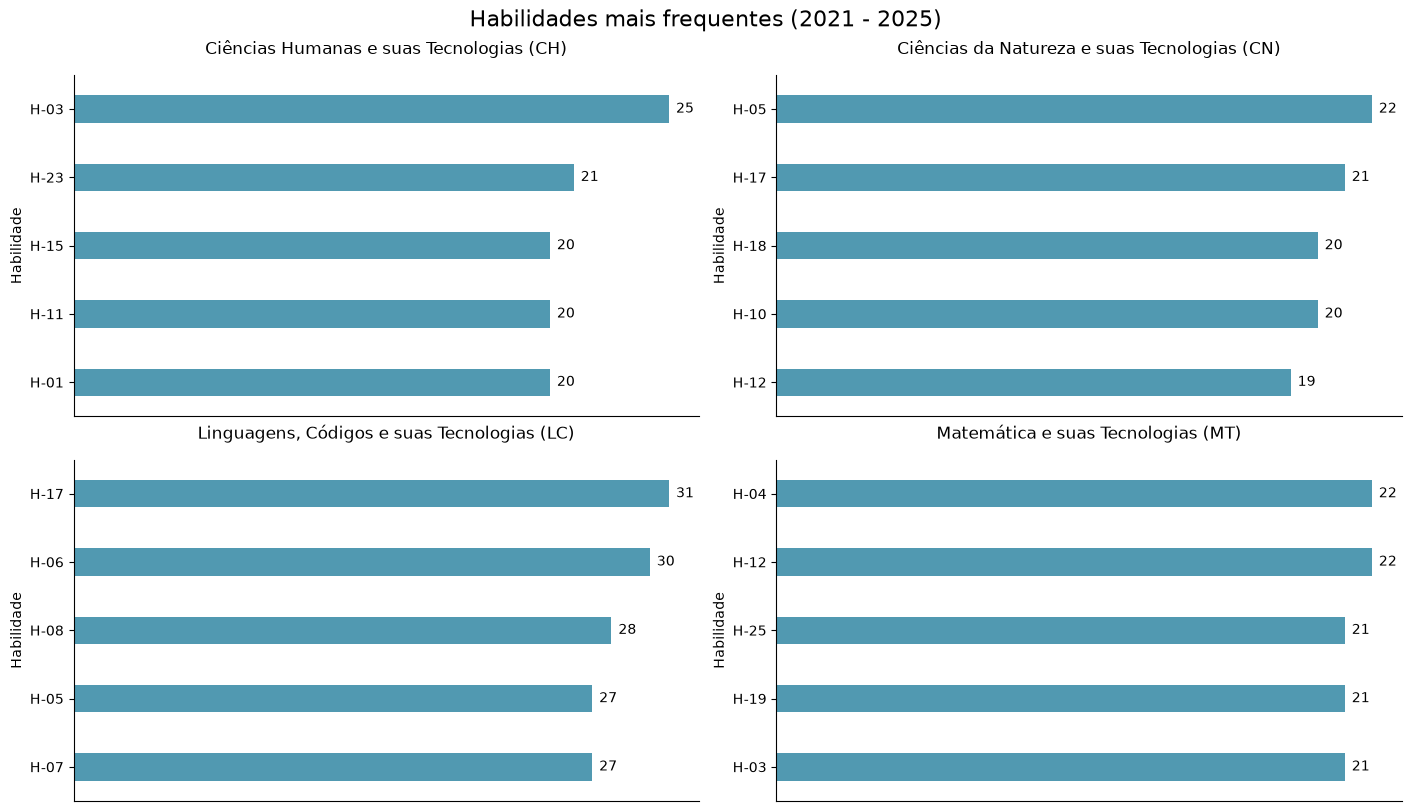

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Criar a moldura de uma figura 2x2
fig, axes = plt.subplots(2, 2, figsize=(14, 8), layout='constrained')

# Definir as áreas do conhecimento
sg_areas = df['Área do conhecimento'].unique()
titulos_areas = [
    "Ciências Humanas e suas Tecnologias (CH)", 
    "Ciências da Natureza e suas Tecnologias (CN)", 
    "Linguagens, Códigos e suas Tecnologias (LC)", 
    "Matemática e suas Tecnologias (MT)"
]

# criar uma lista para armazenar as legendas com as descrições.
lista_legenda = []

# O axes.flatten() transforma a matriz 2x2 em uma lista simples de 4 espaços para o loop. O zip junta cada item da lista (o gráfico) com seu respectivo espaço
for ax, area, titulo in zip(axes.flatten(), sg_areas, titulos_areas):
    
    # Filtrar o dataframe original apenas para a área da rodada
    df_filtrado = df[df['Área do conhecimento'] == area].copy()
    df_filtrado = df_filtrado.sort_values(by='Quantidade', ascending=False).head(5)
    df_filtrado['Habilidade'] = 'H-' + df_filtrado['Habilidade'].astype(str).str.zfill(2) # zfill serve para adicionar um zero a esquerda de números que só tem 1 algarismo
    lista_legenda.append(df_filtrado) # salvar esse df filtrado como elemento da lista de legendas
    
    # Plota o gráfico no eixo (ax) específico da rodada
    sns.barplot(
        data=df_filtrado,
        y='Habilidade',
        x='Quantidade',
        orient='h',
        width=0.4,
        ax=ax,
        alpha=0.8,
        color="#118AB2",
        legend=False
    )
    
    # Formatação  de cada quadro
    ax.set_title(titulo, fontsize=12, pad=15)
    ax.set_ylabel("Habilidade")
    ax.set_xlabel("")

    # Remove a escala do eixo X
    ax.set_xticks([])

    # Adiciona os rótulos de dados no final de cada barra
    ax.bar_label(ax.containers[0], padding=5, fontsize=10, color="#000000")
    
    # Remove as bordas
    sns.despine(ax=ax)

df_top5_legendas = pd.concat(lista_legenda) # junta a lista de legendas em um dataframe só

# título geral
fig.suptitle('Habilidades mais frequentes (2021 - 2025)', fontsize=16)

# Exportando o gráfico final em alta resolução
plt.savefig('../graficos/habilidades_frequencia.png', dpi=300)

plt.show()

## Conclusões

Nossa conclusão é feita por área do conhecimento. Para isso vamos analisar as habilidades mais frequentes e sua descrição.

In [4]:
pd.set_option('display.max_colwidth', None) # remover o limite de largura das colunas para mostrar a descrição completa

display(
    df_top5_legendas[:5].style # intervalo apenas de CH
    .hide(axis="index") # não exibir a coluna de índice
    .set_properties(**{'text-align': 'left'}) # alinhar o texto das descrições a esquerda para facilitar leitura
)

pd.reset_option('display.max_colwidth') # devolver o limite de largura das colunas

Área do conhecimento,Habilidade,Descrição,Quantidade,ranking
CH,H-03,associar as manifestações culturais do presente aos seus processos históricos.,25,1
CH,H-23,analisar a importância dos valores éticos na estruturação política das sociedades.,21,2
CH,H-15,"avaliar criticamente conflitos culturais, sociais, políticos, econômicos ou ambientais ao longo da história.",20,3
CH,H-11,identificar registros de práticas de grupos sociais no tempo e no espaço.,20,4
CH,H-01,interpretar historicamente e/ou geograficamente fontes documentais acerca de aspectos da cultura.,20,5


Na área de ciências humanas notamos claro destaque para o entendimento das manifestações culturais, suas origens e sua representatividade nos contextos histórico e atual (H-03). Essa habilidade, juntamente com a identificação de registros sociais (H-11) e a avaliação de conflitos ao longo da história (H-15), mostra que a prova tem preferência por avaliar domínio em história e sociologia, com frequente relação entre essas duas disciplinas.

In [5]:
pd.set_option('display.max_colwidth', None) # remover o limite de largura das colunas para mostrar a descrição completa

display(
    df_top5_legendas[5:10].style # intervalo apenas de CN
    .hide(axis="index") # não exibir a coluna de índice
    .set_properties(**{'text-align': 'left'}) # alinhar o texto das descrições a esquerda para facilitar leitura
)

pd.reset_option('display.max_colwidth') # devolver o limite de largura das colunas

Área do conhecimento,Habilidade,Descrição,Quantidade,ranking
CN,H-05,dimensionar circuitos ou dispositivos elétricos de uso cotidiano.,22,1
CN,H-17,"relacionar informações apresentadas em diferentes formas de linguagem e representação usadas nas ciências físicas, químicas ou biológicas, como texto discursivo, gráficos, tabelas, relações matemáticas ou linguagem simbólica.",21,2
CN,H-18,"relacionar propriedades físicas, químicas ou biológicas de produtos, sistemas ou procedimentos tecnológicos às finalidades a que se destinam.",20,3
CN,H-10,"analisar perturbações ambientais, identificando fontes, transporte e(ou) destino dos poluentes ou prevendo efeitos em sistemas naturais, produtivos ou sociais.",20,4
CN,H-12,"avaliar impactos em ambientes naturais decorrentes de atividades sociais ou econômicas, considerando interesses contraditórios.",19,5


Em ciências da natureza vemos nas habilidades de dimensionar circuitos ou dispositivos elétricos (H-05), Analisar perturbações ambientais (H-10) e impactos ambientais (H-12) a tendência da prova em avaliar o entendimento do estudante sobre os fenômenos do cotidiano, suas causas e consequências. Há ainda uma avaliação técnica, incluindo leitura e interpretação de dados (H-17) e explicações de processos (H-18).

In [6]:
pd.set_option('display.max_colwidth', None) # remover o limite de largura das colunas para mostrar a descrição completa

display(
    df_top5_legendas[10:15].style # intervalo apenas de LC
    .hide(axis="index") # não exibir a coluna de índice
    .set_properties(**{'text-align': 'left'}) # alinhar o texto das descrições a esquerda para facilitar leitura
)

pd.reset_option('display.max_colwidth') # devolver o limite de largura das colunas

Área do conhecimento,Habilidade,Descrição,Quantidade,ranking
LC,H-17,reconhecer a presença de valores sociais e humanos atualizáveis e permanentes no patrimônio literário nacional.,31,1
LC,H-06,"utilizar os conhecimentos da lem e de seus mecanismos como meio de ampliar as possibilidades de acesso a informações, tecnologias e culturas.",30,2
LC,H-08,reconhecer a importância da produção cultural em lem como representação da diversidade cultural e linguística.,28,3
LC,H-05,associar vocábulos e expressões de um texto em lem ao seu tema.,27,4
LC,H-07,"relacionar um texto em lem, as estruturas linguísticas, sua função e seu uso social.",27,5


O primeiro destaque de LC é que as quantidades são as mais altas entre os top 5 analisados. Isso indica que há menor dispersão (maior repetição) na quantidade total das frequências das habilidades. 

Quanto ao ranking em si, vemos de início a presença das 4 habilidades relacionadas à língua estrangeira moderna (LEM) entre as 5 mais frequentes. Essa presença já era esperada, pois sempre há 5 questões da prova garantidas para LEM. Como a competência relacionada a LEM só tem 4 habilidades é inevitável a alta frequência, inclusive com a certeza de pelo menos uma repetição de habilidade por prova.

Acima das habilidades em LEM está o reconhecimento de valores na literatura nacional (H-17). É interessante notar que a habilidade mais avaliada não é necessariamente algum requisito técnico da língua portuguesa, mas sim relacionada à literatura. Tal fato confirma a tendência do ENEM em ser uma prova menos focada no técnico e mais focada no contextual, priorizando avaliar a capacidade do aluno de interpretar e entender as diversas áreas do conhecimento em que está inserido em seu cotidiano.

In [7]:
pd.set_option('display.max_colwidth', None) # remover o limite de largura das colunas para mostrar a descrição completa

display(
    df_top5_legendas[15:].style # intervalo apenas de MT
    .hide(axis="index") # não exibir a coluna de índice
    .set_properties(**{'text-align': 'left'}) # alinhar o texto das descrições a esquerda para facilitar leitura
)

pd.reset_option('display.max_colwidth') # devolver o limite de largura das colunas

Área do conhecimento,Habilidade,Descrição,Quantidade,ranking
MT,H-04,avaliar a razoabilidade de um resultado numérico na construção de argumentos sobre afirmações quantitativas.,22,1
MT,H-12,resolver situação-problema que envolva medidas de grandezas.,22,2
MT,H-25,resolver problema com dados apresentados em tabelas ou gráficos.,21,3
MT,H-19,identificar representações algébricas que expressem a relação entre grandezas.,21,4
MT,H-03,resolver situação-problema envolvendo conhecimentos numéricos.,21,5


Diferente da área de LC, em MT vemos a menor variação na quantidade de distribuição dentro do top 5. O fato de termos 45 questões e 30 habilidades para uma única disciplina permite melhor distribuição das questões.

Três das cinco habilidades (H-12, H-25 e H-03) tratam de resolver situações-problema. Isso reforça o foco do ENEM em contextualização, mostrando ao estudante que a matemática está presente em todas as áreas e aspectos da vida cotidiana. A razoabilidade de um resultado (H-04) avalia se o aluno tem noção de resultado esperado. A leitura de tabelas e gráficos (H-25) busca compreender a capacidade do candidato em analisar e interpretar dados estatísticos.

Em resumo, o mapeamento das habilidades mais frequentes comprova a identidade do ENEM. não é um exame de memorização técnica isolada, mas de leitura de mundo. Seja interpretando estatísticas em matemática, impactos ambientais em ciências da natureza ou conflitos em ciências humanas, a prova exige que o candidato aplique o conhecimento técnico para resolver problemas do cotidiano.